# Exploratory Data Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_pickle("../data/processed/subnetwork.pkl")

In [3]:
data.head()

,betriebstag,fahrt_bezeichner,linien_id,linien_text,verkehrsmittel_text,zusatzfahrt_tf,faellt_aus_tf,bpuic,haltestellen_name,ankunftszeit,...,an_prognose_status,abfahrtszeit,ab_prognose,ab_prognose_status,durchfahrt_tf,sloid,ankunftsverspatung,an_versp_sek,abfahrtsverspatung,an_versp_min
201,2026-11-01,ch:1:sjyid:100001:2599-001,2599,IR35,IR,False,False,8507000.0,Bern,NaT,...,NaN,2026-11-01 22:33:00,2026-11-01 22:38:40,REAL,False,ch:1:sloid:7000,False,NaN,True,NaN
202,2026-11-01,ch:1:sjyid:100001:2599-001,2599,IR35,IR,False,False,8508008.0,Herzogenbuchsee,2026-11-01 23:03:00,...,REAL,2026-11-01 23:04:00,2026-11-01 23:04:58,REAL,False,ch:1:sloid:8008,False,-65.0,False,-1.083333
332,2026-11-01,ch:1:sjyid:100001:279-002,279,ICE,ICE,False,False,8503000.0,Zürich HB,2026-11-01 15:00:00,...,REAL,2026-11-01 15:07:00,2026-11-01 15:09:06,REAL,False,ch:1:sloid:3000,True,-228.0,False,-3.800000
367,2026-11-01,ch:1:sjyid:100001:30100-012,30100,IC61,IC,True,False,8507000.0,Bern,2026-11-01 17:56:00,...,REAL,2026-11-01 18:04:00,2026-11-01 18:04:50,REAL,False,ch:1:sloid:7000,False,-10.0,False,-0.166667
661,2026-11-01,ch:1:sjyid:100001:333-002,333,IC61,IC,False,False,8507000.0,Bern,2026-11-01 08:56:00,...,REAL,2026-11-01 09:04:00,2026-11-01 09:04:39,REAL,False,ch:1:sloid:7000,False,-58.0,False,-0.966667


## Delay Statistics

In [4]:
data["an_versp_min"].describe()

count    21973.000000
mean        -0.728341
std          2.201609
min        -75.966667
25%         -1.100000
50%         -0.350000
75%          0.183333
max          6.183333
Name: an_versp_min, dtype: float64

In [5]:
delay_summary = pd.DataFrame({
    "metric": ["Observed arrival delays", "Early arrivals", "More than 10 minutes early", "On-time or early arrivals", 
               "Late arrivals", "More than 3 minutes late", "More than 5 minutes late", "More than 10 minutes late", 
               "More than 15 minutes late"],
    "value": [data["an_versp_min"].notna().sum(), (data["an_versp_min"] < 0).sum(), (data["an_versp_min"] < -10).sum(), 
              (data["an_versp_min"] <= 0).sum(), (data["an_versp_min"] > 0).sum(), (data["an_versp_min"] > 3).sum(), 
              (data["an_versp_min"] > 5).sum(), (data["an_versp_min"] > 10).sum(), (data["an_versp_min"] > 15).sum()]
})
delay_summary

,metric,value
0,Observed arrival delays,21973
1,Early arrivals,14594
2,More than 10 minutes early,140
3,On-time or early arrivals,14755
4,Late arrivals,7218
5,More than 3 minutes late,7
6,More than 5 minutes late,3
7,More than 10 minutes late,0
8,More than 15 minutes late,0


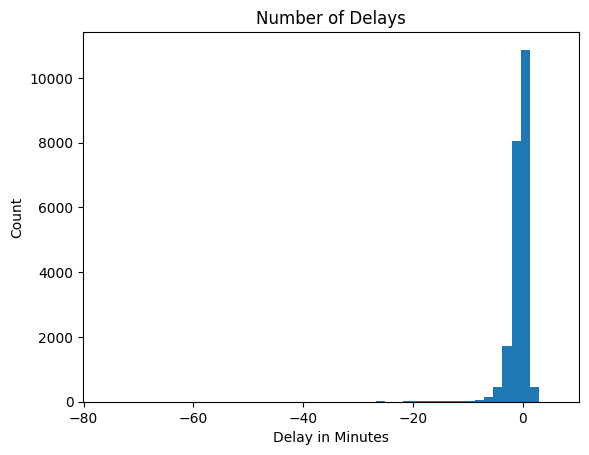

In [6]:
plt.hist(data["an_versp_min"], bins = 50)
plt.title("Number of Delays")
plt.xlabel("Delay in Minutes")
plt.ylabel("Count")
plt.show()

## Observations by date

In [7]:
# number of stop records, train runs, lines and stations per operating day
daily_summary = (
    data.groupby("betriebstag")
    .agg(
        stop_records = ("fahrt_bezeichner", "size"),
        train_runs = ("fahrt_bezeichner", "nunique"),
        lines = ("linien_text", "nunique"),
        stations = ("haltestellen_name", "nunique"), 
        delay_mean = ("an_versp_min", "mean")
    )
)

daily_summary

,stop_records,train_runs,lines,stations,delay_mean
betriebstag,,,,,
2026-11-01,3567,1099,33,13,-0.396478
2026-11-02,3741,1164,29,13,-0.684019
2026-11-03,3755,1166,29,13,-0.840838
2026-11-04,3757,1171,29,13,-0.742528
2026-11-05,3740,1164,29,13,-0.639671
2026-11-06,3765,1167,30,13,-1.018061
2026-11-07,3650,1124,34,13,-0.757009


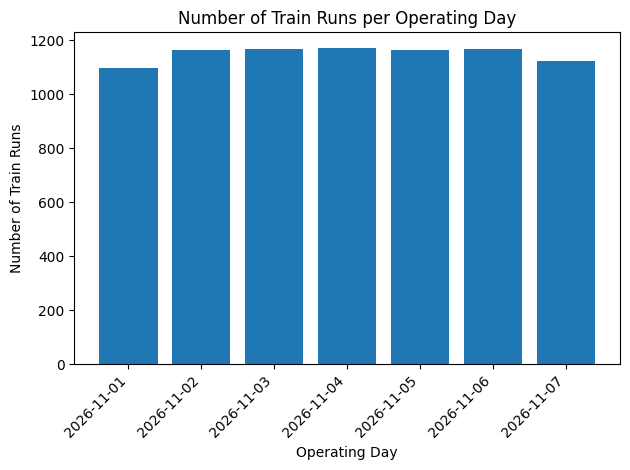

In [8]:
plt.bar(daily_summary.index.astype(str),daily_summary["train_runs"])
plt.title("Number of Train Runs per Operating Day")
plt.xlabel("Operating Day")
plt.ylabel("Number of Train Runs")
plt.xticks(rotation=45, ha = 'right')
plt.tight_layout()
plt.show()

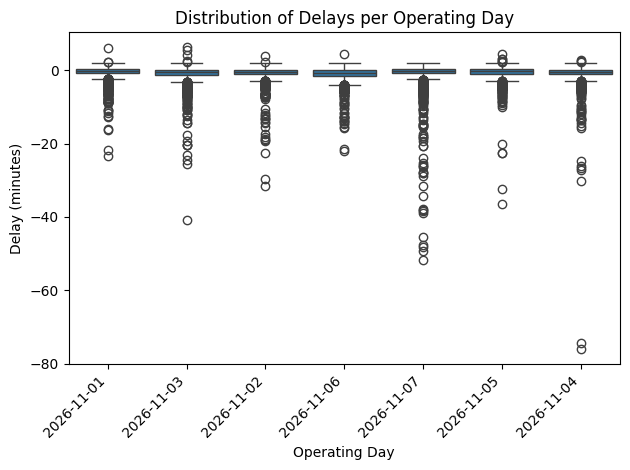

In [9]:
sns.boxplot(data=data, x="betriebstag", y="an_versp_min")

plt.title("Distribution of Delays per Operating Day")
plt.xlabel("Operating Day")
plt.ylabel("Delay (minutes)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Observations by stop

In [10]:
stops_summary = (
    data.groupby("haltestellen_name")
    .agg(
        stop_records = ("fahrt_bezeichner", "size"),
        train_runs = ("fahrt_bezeichner", "nunique"),
        lines = ("linien_text", "nunique"), 
        delay_mean = ("an_versp_min", "mean")
    )
)

column_order = ["Bern", "Burgdorf", "Wynigen", "Herzogenbuchsee", "Langenthal", "Olten", 
                "Aarau", "Lenzburg", "Brugg AG", "Baden", "Dietikon", "Zürich Altstetten", "Zürich HB"]
stops_summary = stops_summary.reindex(column_order)

stops_summary

,stop_records,train_runs,lines,delay_mean
haltestellen_name,,,,
Bern,1678,319,13,-1.255605
Burgdorf,117,39,3,-1.888746
Wynigen,11,4,3,-2.403030
Herzogenbuchsee,117,39,3,-1.932479
Langenthal,651,118,5,-0.713174
Olten,3307,567,22,-0.840728
Aarau,3058,499,19,-0.870263
Lenzburg,1690,287,15,-0.890347
Brugg AG,2463,400,9,-0.340415


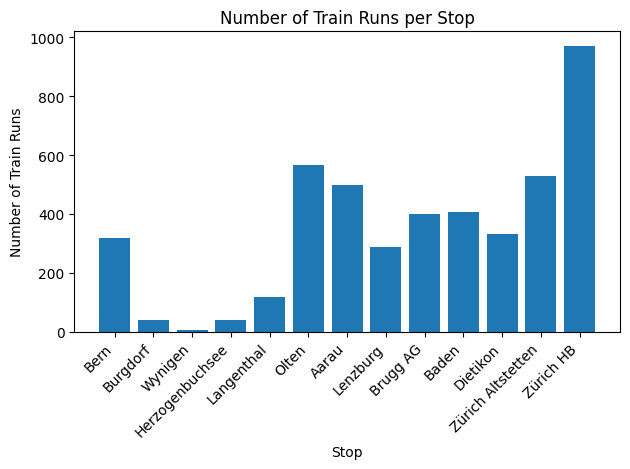

In [11]:
plt.bar(stops_summary.index.astype(str), stops_summary["train_runs"])
plt.title("Number of Train Runs per Stop")
plt.xlabel("Stop")
plt.ylabel("Number of Train Runs")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

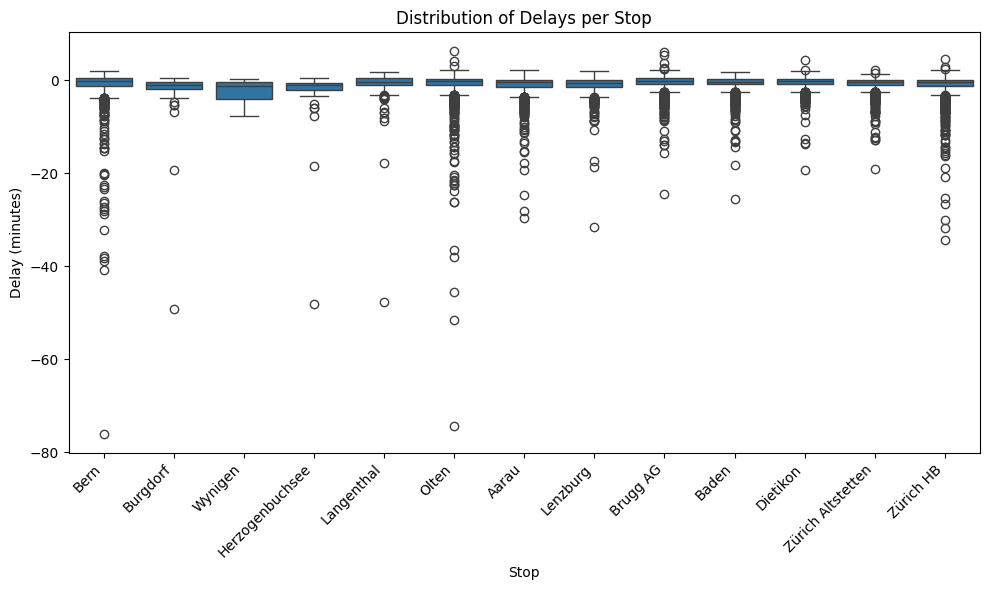

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x="haltestellen_name", y="an_versp_min", order = column_order)

plt.title("Distribution of Delays per Stop")
plt.xlabel("Stop")
plt.ylabel("Delay (minutes)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()